<a href="https://colab.research.google.com/github/mohamadnurtaufiq/UTS-Machine-Learning-kelompok-14/blob/main/classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# UTS Machine Learning — Task 2: Classification (Fraud Detection)





In [31]:
!pip -q install imbalanced-learn

In [32]:
# ============================================================
# UTS MACHINE LEARNING - TASK 2: CLASSIFICATION (FRAUD DETECTION)
# File input : klasifikasi_train.csv.gz, klasifikasi_test.csv.gz
# File output: prediksi_klasifikasi.csv
# ============================================================

# 0. INSTALLASI (jalankan sekali di Google Colab)
# !pip -q install imbalanced-learn

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    average_precision_score, roc_auc_score, brier_score_loss,
    precision_score, recall_score, f1_score, confusion_matrix,
    classification_report
)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler

RANDOM_STATE = 42
REVIEW_COST = 25_000



In [35]:
# ------------------------------------------------------------
# 1. BACA DATASET
# ------------------------------------------------------------
# Membaca dataset dari file .csv yang tersedia di Colab
TRAIN_PATH = "/content/klasifikasi_train.csv"
TEST_PATH = "/content/klasifikasi_test.csv"

train = pd.read_csv(TRAIN_PATH)
test = pd.read_csv(TEST_PATH)

print("Ukuran train:", train.shape)
print("Ukuran test :", test.shape)
print("Periode train:", train["waktu"].min(), "s.d.", train["waktu"].max())
print("Periode test :", test["waktu"].min(), "s.d.", test["waktu"].max())

Ukuran train: (82604, 85)
Ukuran test : (19576, 84)
Periode train: 2025-01-01 00:35:01 s.d. 2025-08-31 23:51:49
Periode test : 2025-09-01 00:20:30 s.d. 2025-10-31 23:57:22


In [36]:
# ------------------------------------------------------------
# 2. DATA AUDIT
# ------------------------------------------------------------
print("\\nDistribusi target:")
print(train["is_fraud"].value_counts())
print("\\nPersentase fraud:", round(train["is_fraud"].mean() * 100, 4), "%")
print("\\nMissing value terbanyak:")
print(train.isna().sum().sort_values(ascending=False).head(15))
print("\\nDuplikasi ID transaksi:", train["id_transaksi"].duplicated().sum())


\nDistribusi target:
is_fraud
0.0    82088
1.0      515
Name: count, dtype: int64
\nPersentase fraud: 0.6235 %
\nMissing value terbanyak:
menit_sejak_trx_terakhir    21062
rasio_nominal_rata2         21062
v33                             1
v32                             1
v31                             1
v36                             1
v37                             1
v38                             1
v39                             1
v40                             1
v41                             1
v42                             1
v43                             1
v44                             1
v45                             1
dtype: int64
\nDuplikasi ID transaksi: 0


In [38]:
# ------------------------------------------------------------
# 3. FEATURE ENGINEERING DAN FEATURE AUDIT
# ------------------------------------------------------------
TARGET = "is_fraud"
ID_COL = "id_transaksi"

def buat_fitur(data):
    """Membuat fitur yang tersedia pada saat transaksi berlangsung."""
    df = data.copy()

    waktu = pd.to_datetime(df["waktu"], errors="coerce")
    df["bulan_transaksi"] = waktu.dt.month
    df["hari_dalam_minggu"] = waktu.dt.dayofweek
    df["akhir_pekan"] = (waktu.dt.dayofweek >= 5).astype("int8")

    # Fitur perilaku turunan dari riwayat transaksi yang sudah tersedia.
    df["rasio_trx_1j_24j"] = df["trx_1j"] / (df["trx_24j" ] + 1)
    df["rasio_trx_24j_7h"] = df["trx_24j"] / (df["trx_7h" ] + 1)
    df["nominal_per_trx_24j"] = df["nominal_24j"] / (df["trx_24j" ] + 1)

    # ID unik tidak digunakan langsung sebagai prediktor.
    # flag_review_manual dikeluarkan karena bisa merupakan informasi
    # yang muncul setelah transaksi ditinjau oleh tim risiko.
    kolom_dihapus = [
        "id_transaksi", "id_pengguna", "id_merchant",
        "waktu", "flag_review_manual", TARGET
    ]
    df = df.drop(columns=kolom_dihapus, errors="ignore")
    return df

X = buat_fitur(train)
y = train[TARGET].fillna(0).astype(int)
X_test = buat_fitur(test)

# Menyamakan kolom train dan test.
X_test = X_test.reindex(columns=X.columns)

kolom_kategori = X.select_dtypes(include=["object", "category"]).columns.tolist()
kolom_numerik = [c for c in X.columns if c not in kolom_kategori]

print("\nJumlah fitur:", X.shape[1])
print("Fitur kategori:", kolom_kategori)
print("Jumlah fitur numerik:", len(kolom_numerik))


Jumlah fitur: 85
Fitur kategori: ['kategori_merchant', 'kanal', 'tipe_perangkat', 'email_domain']
Jumlah fitur numerik: 81


In [39]:
# ------------------------------------------------------------
# 4. TIME-BASED SPLIT
# Train model: Januari-Mei 2025
# Calibration: Juni 2025
# Validation: Juli-Agustus 2025
# ------------------------------------------------------------
tanggal = pd.to_datetime(train["waktu"])
idx_model = tanggal < "2025-06-01"
idx_calib = (tanggal >= "2025-06-01") & (tanggal < "2025-07-01")
idx_valid = tanggal >= "2025-07-01"

X_model, y_model = X.loc[idx_model], y.loc[idx_model]
X_calib, y_calib = X.loc[idx_calib], y.loc[idx_calib]
X_valid, y_valid = X.loc[idx_valid], y.loc[idx_valid]
nominal_valid = train.loc[idx_valid, "nominal"].astype(float).to_numpy()

print("\\nJumlah data model:", len(X_model), "| fraud:", int(y_model.sum()))
print("Jumlah data kalibrasi:", len(X_calib), "| fraud:", int(y_calib.sum()))
print("Jumlah data validasi:", len(X_valid), "| fraud:", int(y_valid.sum()))

\nJumlah data model: 50553 | fraud: 345
Jumlah data kalibrasi: 10136 | fraud: 56
Jumlah data validasi: 21915 | fraud: 114


In [40]:
# ------------------------------------------------------------
# 5. PREPROCESSING
# ------------------------------------------------------------
preprocessor = ColumnTransformer(
    transformers=[
        ("numerik", Pipeline(steps=[
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler(with_mean=False))
        ]), kolom_numerik),
        ("kategori", Pipeline(steps=[
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ]), kolom_kategori)
    ],
    remainder="drop"
)

In [41]:
# ------------------------------------------------------------
# 6. TIGA PENDEKATAN UNTUK DATA IMBALANCED
# A. Logistic Regression + class weighting
# B. Random Forest + class weighting
# C. Logistic Regression + random undersampling
# ------------------------------------------------------------
model_dict = {
    "LogisticRegression_ClassWeight": Pipeline(steps=[
        ("prep", preprocessor),
        ("model", LogisticRegression(
            class_weight="balanced",
            max_iter=700,
            solver="saga",
            n_jobs=-1,
            random_state=RANDOM_STATE
        ))
    ]),

    "RandomForest_ClassWeight": Pipeline(steps=[
        ("prep", preprocessor),
        ("model", RandomForestClassifier(
            n_estimators=120,
            max_depth=16,
            min_samples_leaf=8,
            class_weight="balanced_subsample",
            n_jobs=-1,
            random_state=RANDOM_STATE
        ))
    ]),

    "LogisticRegression_Undersampling": ImbPipeline(steps=[
        ("prep", preprocessor),
        ("sampling", RandomUnderSampler(random_state=RANDOM_STATE)),
        ("model", LogisticRegression(
            max_iter=700,
            solver="saga",
            n_jobs=-1,
            random_state=RANDOM_STATE
        ))
    ])
}

In [42]:
# ------------------------------------------------------------
# 7. KALIBRASI PROBABILITAS (PLATT / SIGMOID CALIBRATION)
# Model dilatih pada Jan-Mei, kalibrator pada Juni,
# lalu dievaluasi pada Juli-Agustus.
# ------------------------------------------------------------
def probabilitas_mentah(model, data):
    return model.predict_proba(data)[:, 1]

def latih_kalibrator(prob, label):
    # Kalibrasi sigmoid menggunakan log-odds probabilitas model.
    eps = 1e-6
    p = np.clip(np.asarray(prob), eps, 1 - eps)
    logit = np.log(p / (1 - p)).reshape(-1, 1)
    kalibrator = LogisticRegression(solver="lbfgs")
    kalibrator.fit(logit, np.asarray(label))
    return kalibrator

def terapkan_kalibrator(kalibrator, prob):
    eps = 1e-6
    p = np.clip(np.asarray(prob), eps, 1 - eps)
    logit = np.log(p / (1 - p)).reshape(-1, 1)
    return kalibrator.predict_proba(logit)[:, 1]

hasil_model = {}
prob_validasi = {}
ringkasan = []

for nama, model in model_dict.items():
    print("\\nMelatih model:", nama)
    model.fit(X_model, y_model)

    prob_calib = probabilitas_mentah(model, X_calib)
    kalibrator = latih_kalibrator(prob_calib, y_calib)

    prob_val_raw = probabilitas_mentah(model, X_valid)
    prob_val = terapkan_kalibrator(kalibrator, prob_val_raw)

    hasil_model[nama] = {
        "model": model,
        "kalibrator": kalibrator
    }
    prob_validasi[nama] = prob_val

    ringkasan.append({
        "model": nama,
        "PR_AUC": average_precision_score(y_valid, prob_val),
        "ROC_AUC": roc_auc_score(y_valid, prob_val),
        "Brier_Score": brier_score_loss(y_valid, prob_val)
    })

tabel_model = pd.DataFrame(ringkasan).sort_values(
    "PR_AUC", ascending=False
)
print("\\nPerbandingan model:")
print(tabel_model.to_string(index=False))

\nMelatih model: LogisticRegression_ClassWeight
\nMelatih model: RandomForest_ClassWeight
\nMelatih model: LogisticRegression_Undersampling
\nPerbandingan model:
                           model   PR_AUC  ROC_AUC  Brier_Score
        RandomForest_ClassWeight 0.424638 0.922900     0.003691
LogisticRegression_Undersampling 0.321996 0.904277     0.004053
  LogisticRegression_ClassWeight 0.315546 0.889801     0.004044


In [43]:
# ------------------------------------------------------------
# 8. THRESHOLD TUNING BERDASARKAN BIAYA
# Biaya review = Rp25.000 per transaksi yang ditandai.
# Fraud yang tidak ditandai menyebabkan kerugian sebesar nominal.
# ------------------------------------------------------------
def hitung_biaya(label, probabilitas, nominal, threshold):
    label = np.asarray(label)
    probabilitas = np.asarray(probabilitas)
    nominal = np.asarray(nominal)

    ditandai = probabilitas >= threshold
    fraud_lolos = (label == 1) & (~ditandai)

    biaya_fraud_lolos = nominal[fraud_lolos].sum()
    biaya_review = ditandai.sum() * REVIEW_COST
    total = biaya_fraud_lolos + biaya_review

    return {
        "threshold": float(threshold),
        "jumlah_ditandai": int(ditandai.sum()),
        "fraud_lolos": int(fraud_lolos.sum()),
        "biaya_fraud_lolos": float(biaya_fraud_lolos),
        "biaya_review": float(biaya_review),
        "total_biaya": float(total)
    }

grid_threshold = np.unique(np.r_[
    np.linspace(0.001, 0.10, 100),
    np.linspace(0.11, 0.99, 45)
])

hasil_biaya = {}
for nama, prob in prob_validasi.items():
    kandidat = [
        hitung_biaya(y_valid, prob, nominal_valid, t)
        for t in grid_threshold
    ]
    hasil_biaya[nama] = min(kandidat, key=lambda x: x["total_biaya"])

tabel_biaya = pd.DataFrame(hasil_biaya).T.sort_values("total_biaya")
print("\\nPerbandingan biaya validasi:")
print(tabel_biaya.to_string())

# Pilih model dengan total biaya validasi terendah.
model_terpilih = tabel_biaya.index[0]
threshold_terpilih = hasil_biaya[model_terpilih]["threshold"]
prob_terpilih = prob_validasi[model_terpilih]

print("\\nModel terpilih:", model_terpilih)
print("Threshold terpilih:", threshold_terpilih)
print("Rincian biaya:", hasil_biaya[model_terpilih])

\nPerbandingan biaya validasi:
                                  threshold  jumlah_ditandai  fraud_lolos  biaya_fraud_lolos  biaya_review  total_biaya
RandomForest_ClassWeight              0.034            350.0         40.0         27323200.0     8750000.0   36073200.0
LogisticRegression_Undersampling      0.064            214.0         58.0         40263700.0     5350000.0   45613700.0
LogisticRegression_ClassWeight        0.060            226.0         60.0         44268400.0     5650000.0   49918400.0
\nModel terpilih: RandomForest_ClassWeight
Threshold terpilih: 0.034
Rincian biaya: {'threshold': 0.034, 'jumlah_ditandai': 350, 'fraud_lolos': 40, 'biaya_fraud_lolos': 27323200.0, 'biaya_review': 8750000.0, 'total_biaya': 36073200.0}


In [44]:
# ------------------------------------------------------------
# 9. EVALUASI MODEL TERPILIH
# ------------------------------------------------------------
pred_valid = (prob_terpilih >= threshold_terpilih).astype(int)

print("\\nClassification report:")
print(classification_report(
    y_valid, pred_valid, digits=4, zero_division=0
))
print("Confusion matrix:")
print(confusion_matrix(y_valid, pred_valid))
print("Precision:", precision_score(y_valid, pred_valid, zero_division=0))
print("Recall   :", recall_score(y_valid, pred_valid, zero_division=0))
print("F1       :", f1_score(y_valid, pred_valid, zero_division=0))
print("PR-AUC   :", average_precision_score(y_valid, prob_terpilih))
print("Brier    :", brier_score_loss(y_valid, prob_terpilih))

\nClassification report:
              precision    recall  f1-score   support

           0     0.9981    0.9873    0.9927     21801
           1     0.2114    0.6491    0.3190       114

    accuracy                         0.9856     21915
   macro avg     0.6048    0.8182    0.6558     21915
weighted avg     0.9941    0.9856    0.9892     21915

Confusion matrix:
[[21525   276]
 [   40    74]]
Precision: 0.21142857142857144
Recall   : 0.6491228070175439
F1       : 0.31896551724137934
PR-AUC   : 0.42463831477626074
Brier    : 0.0036914872630872298


\nRingkasan fraud per bulan:
  bulan  jumlah_transaksi  jumlah_fraud  fraud_rate  median_nominal
2025-01             10437          57.0    0.005461        128000.0
2025-02              9491          57.0    0.006006        130700.0
2025-03             10393          85.0    0.008179        134000.0
2025-04              9606          68.0    0.007080        129900.0
2025-05             10626          78.0    0.007340        127200.0
2025-06             10136          56.0    0.005525        129500.0
2025-07             10889          57.0    0.005235        129000.0
2025-08             11026          57.0    0.005170        127200.0


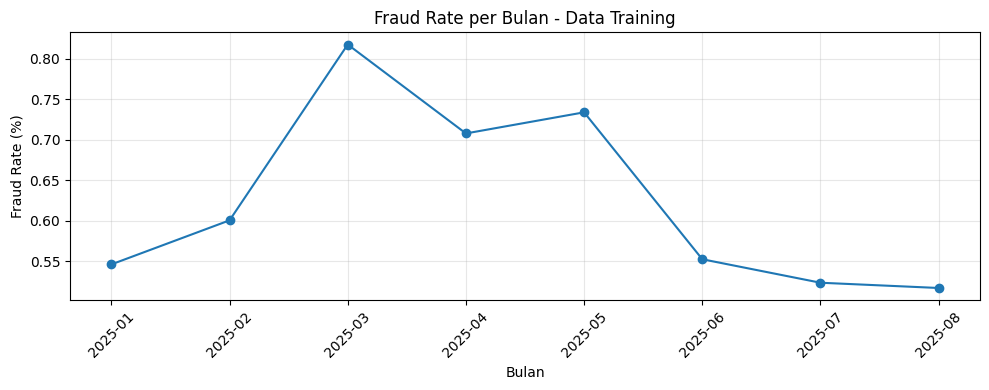

\nFraud rate berdasarkan kanal:
          count    sum      mean
kanal                           
web        5090   96.0  0.018861
kartu     10308  159.0  0.015425
va        12185  101.0  0.008289
aplikasi  36918  124.0  0.003359
qris      18102   35.0  0.001933
\nFraud rate berdasarkan kategori merchant:
                   count   sum      mean
kategori_merchant                       
voucher_game        3679  86.0  0.023376
gadget              3466  48.0  0.013849
emas                1335  17.0  0.012734
top_up_ewallet      4215  49.0  0.011625
fashion             5721  47.0  0.008215
toko_online         6711  55.0  0.008195
pulsa_data          7904  62.0  0.007844
elektronik          9087  67.0  0.007373
kecantikan          3496  23.0  0.006579
jasa_lainnya        1689   7.0  0.004144
olahraga             987   4.0  0.004053
tagihan_listrik     3101   8.0  0.002580
tagihan_air          970   2.0  0.002062
kesehatan           2513   5.0  0.001990
rumah_tangga        3045   6.0  0.001

In [45]:
# ------------------------------------------------------------
# 10. ANALISIS PERUBAHAN POLA FRAUD (PATTERN SHIFT)
# Hanya bisa dihitung pada data train karena test tidak memiliki label.
# ------------------------------------------------------------
analisis_bulan = train.copy()
analisis_bulan["bulan"] = pd.to_datetime(
    analisis_bulan["waktu"]
).dt.to_period("M").astype(str)

ringkasan_bulan = analisis_bulan.groupby("bulan").agg(
    jumlah_transaksi=("is_fraud", "size"),
    jumlah_fraud=("is_fraud", "sum"),
    fraud_rate=("is_fraud", "mean"),
    median_nominal=("nominal", "median")
).reset_index()

print("\\nRingkasan fraud per bulan:")
print(ringkasan_bulan.to_string(index=False))

plt.figure(figsize=(10, 4))
plt.plot(
    ringkasan_bulan["bulan"],
    ringkasan_bulan["fraud_rate"] * 100,
    marker="o"
)
plt.title("Fraud Rate per Bulan - Data Training")
plt.xlabel("Bulan")
plt.ylabel("Fraud Rate (%)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Analisis ringkas per kanal dan kategori merchant.
print("\\nFraud rate berdasarkan kanal:")
print(
    train.groupby("kanal")["is_fraud"]
    .agg(["count", "sum", "mean"])
    .sort_values("mean", ascending=False)
)

print("\\nFraud rate berdasarkan kategori merchant:")
print(
    train.groupby("kategori_merchant")["is_fraud"]
    .agg(["count", "sum", "mean"])
    .sort_values("mean", ascending=False)
)

In [46]:
# ------------------------------------------------------------
# 11. MODEL FINAL UNTUK DATA TEST
# Fit model terpilih pada Januari-Juni.
# Kalibrasi pada Juli.
# Threshold ditentukan pada Agustus.
# ------------------------------------------------------------
tanggal = pd.to_datetime(train["waktu"])
idx_final_fit = tanggal < "2025-07-01"
idx_final_calib = (tanggal >= "2025-07-01") & (tanggal < "2025-08-01")
idx_final_threshold = tanggal >= "2025-08-01"

X_final_fit = X.loc[idx_final_fit]
y_final_fit = y.loc[idx_final_fit]
X_final_calib = X.loc[idx_final_calib]
y_final_calib = y.loc[idx_final_calib]
X_final_threshold = X.loc[idx_final_threshold]
y_final_threshold = y.loc[idx_final_threshold]
nominal_final_threshold = train.loc[
    idx_final_threshold, "nominal"
].astype(float).to_numpy()

# Buat ulang model terpilih dengan konfigurasi yang sama.
final_model = model_dict[model_terpilih]
final_model.fit(X_final_fit, y_final_fit)

prob_calib_final_raw = probabilitas_mentah(final_model, X_final_calib)
final_calibrator = latih_kalibrator(
    prob_calib_final_raw, y_final_calib
)

prob_threshold_raw = probabilitas_mentah(
    final_model, X_final_threshold
)
prob_threshold = terapkan_kalibrator(
    final_calibrator, prob_threshold_raw
)

# Cari threshold final hanya pada periode Agustus.
kandidat_final = [
    hitung_biaya(
        y_final_threshold,
        prob_threshold,
        nominal_final_threshold,
        t
    )
    for t in grid_threshold
]
threshold_final = min(
    kandidat_final, key=lambda x: x["total_biaya"]
)["threshold"]

print("\\nThreshold final dari validasi Agustus:", threshold_final)

# Prediksi data test September-Oktober 2025.
prob_test_raw = probabilitas_mentah(final_model, X_test)
prob_test = terapkan_kalibrator(final_calibrator, prob_test_raw)
tandai_test = (prob_test >= threshold_final).astype(int)

submission = pd.DataFrame({
    "id_transaksi": test[ID_COL],
    "prob": prob_test,
    "tandai": tandai_test
})

OUTPUT_PATH = "/content/prediksi_klasifikasi.csv"
submission.to_csv(OUTPUT_PATH, index=False)

\nThreshold final dari validasi Agustus: 0.04


In [47]:
# ------------------------------------------------------------
# 12. VALIDASI FORMAT OUTPUT
# ------------------------------------------------------------
hasil_cek = pd.read_csv(OUTPUT_PATH)

assert list(hasil_cek.columns) == [
    "id_transaksi", "prob", "tandai"
]
assert len(hasil_cek) == len(test)
assert hasil_cek["prob"].between(0, 1).all()
assert set(hasil_cek["tandai"].unique()).issubset({0, 1})
assert hasil_cek["id_transaksi"].equals(test["id_transaksi"])

print("\\nBERHASIL membuat:", OUTPUT_PATH)
print("Jumlah baris:", len(hasil_cek))
print("Jumlah transaksi ditandai:", int(hasil_cek["tandai"].sum()))
print("\\nContoh hasil:")
print(hasil_cek.head())

# Di Google Colab, jalankan sel berikut untuk mengunduh file:
# from google.colab import files
# files.download("prediksi_klasifikasi.csv")

\nBERHASIL membuat: /content/prediksi_klasifikasi.csv
Jumlah baris: 19576
Jumlah transaksi ditandai: 323
\nContoh hasil:
  id_transaksi      prob  tandai
0   T502861791  0.009276       0
1   T980390558  0.000222       0
2   T657838379  0.002890       0
3   T985886276  0.000011       0
4   T852019235  0.001600       0
